# News Article Classification Using Natural Language Processing (NLP) and Machine Learning

**Project level:** Intermediate  
**Platform:** Jupyter Notebook  
**Dataset:** AG News Classification Dataset  
**Problem type:** Supervised multi-class text classification  
**Target classes:** World, Sports, Business, Sci/Tech

---

## Project Introduction

News websites publish thousands of articles every day. Organizing every article manually into the correct category takes time and effort. This project develops a machine learning system that reads a news headline and description and predicts its category.

The model will classify each article into one of four categories:

1. **World** – international events and global news.
2. **Sports** – games, tournaments, teams, and athletes.
3. **Business** – companies, finance, markets, and the economy.
4. **Sci/Tech** – science, computers, technology, and innovation.

### Project objective

Build, evaluate, save, and deploy a text classification model using a complete NLP workflow.

### Tools and libraries

- Python – programming language.
- Pandas and NumPy – data handling.
- Matplotlib and Seaborn – data visualization.
- Scikit-learn – preprocessing, model training, and evaluation.
- Hugging Face Datasets – dataset loading.
- Joblib – saving and loading the trained pipeline.
- Gradio – creating a simple web interface.

### Workflow followed

Business problem → Objective and target check → Data collection → EDA → Feature engineering → Input/output separation → Train-test split → Text preprocessing → Model building → Evaluation → Hyperparameter tuning → Best model → Final evaluation → Save/load → Deployment → Monitoring.


# STEP 1 – BUSINESS PROBLEM STATEMENT

## 1.1 Understanding the business problem

News publishers receive a large number of articles from reporters, agencies, and online sources. Each article needs to be placed in a suitable category so that readers can find related content easily.

Manual categorization can be slow and may produce inconsistent results. An automated NLP system can read the article text and suggest the correct category.

## 1.2 Business problem

**How can we automatically classify a news article into World, Sports, Business, or Sci/Tech based on its text?**

## 1.3 Expected business outcome

- Reduce manual article classification.
- Organize news articles consistently.
- Make searching and filtering articles easier.
- Support faster content management.

## 1.4 Project input and output

- **Input:** News headline and description.
- **Output:** Predicted news category.

This is a supervised multi-class classification problem because the training examples have known category labels.


# STEP 2 – OBJECTIVE AND TARGET IDENTIFICATION

## 2.1 What is the objective?

The objective is to predict the category of a news article from its text.

## 2.2 Check whether the target is present

Before training a supervised model, we must confirm that the dataset contains a target column.

For this project:
- Input feature: article text.
- Target variable: category label.
- Number of classes: four.

The AG News dataset provides labels. Therefore, supervised learning is suitable.

## 2.3 Target label mapping

The dataset uses numeric labels. We will map them to readable category names.

| Numeric label | Category |
|---:|---|
| 0 | World |
| 1 | Sports |
| 2 | Business |
| 3 | Sci/Tech |

**Important:** If a dataset does not contain target labels, we cannot directly train this supervised classifier until suitable labels are collected or created.


# STEP 3 – DATA COLLECTION

## 3.1 Dataset selection

We use the **AG News Classification Dataset**, a commonly used dataset for news topic classification.

It contains news titles, descriptions, and one of four topic labels.

## 3.2 Dataset source

Hugging Face dataset page:  
https://huggingface.co/datasets/fancyzhx/ag_news

The dataset loader downloads the training and test partitions. An internet connection is required for the first download.

## 3.3 Install the required libraries

Run this cell once in Jupyter. If a package is already installed, pip will generally leave it in place or update it as needed.


In [18]:
%pip install -q datasets pandas numpy matplotlib seaborn scikit-learn joblib gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: C:\Users\bhuva\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


## 3.4 Import the libraries required for data collection and project setup

We import the libraries used throughout the notebook. Later sections also show their own imports where a new library or function is introduced, so each section can be understood independently.


In [19]:
import re
import html
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42

print("Basic libraries imported successfully.")

Basic libraries imported successfully.


## 3.5 Load the AG News dataset

We use `load_dataset()` from Hugging Face Datasets.

The dataset has two official partitions:
- `train`: used for model development and training.
- `test`: kept aside for final evaluation.

We combine the title and description into one text column because both contain useful information for predicting the category.


In [20]:

# STEP 3.5 – LOAD THE AG NEWS DATASET

# Load locally downloaded CSV files
train_df = pd.read_csv(
    "AG_News_Dataset/train.csv",
    header=None
)

test_df = pd.read_csv(
    "AG_News_Dataset/test.csv",
    header=None
)

# Assign column names
train_df.columns = ["label", "title", "description"]
test_df.columns = ["label", "title", "description"]

# Convert labels into readable categories
label_names = {
    1: "World",
    2: "Sports",
    3: "Business",
    4: "Sci/Tech"
}

train_df["category"] = train_df["label"].map(label_names)
test_df["category"] = test_df["label"].map(label_names)

# Combine title and description into article text
train_df["text"] = (
    train_df["title"].fillna("").astype(str) + " " +
    train_df["description"].fillna("").astype(str)
).str.strip()

test_df["text"] = (
    test_df["title"].fillna("").astype(str) + " " +
    test_df["description"].fillna("").astype(str)
).str.strip()

# Display dataset information
print("AG News Dataset Loaded Successfully!")
print("-" * 50)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\nCategory Distribution:")
print(train_df["category"].value_counts())

print("\nTraining Data Preview:")
display(train_df[["title", "description", "text", "category"]].head())

print("\nTesting Data Preview:")
display(test_df[["title", "description", "text", "category"]].head())


AG News Dataset Loaded Successfully!
--------------------------------------------------
Training Dataset Shape: (120000, 5)
Testing Dataset Shape: (7600, 5)

Category Distribution:
category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64

Training Data Preview:


,title,description,text,category
0,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.","Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cyn...",Business
1,Carlyle Looks Toward Commercial Aerospace (Reuters),"Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\contr...","Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a rep...",Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over...,Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and th...,Business
3,Iraq Halts Oil Exports from Main Southern Pipeline (Reuters),Reuters - Authorities have halted oil export\flows from the main pipeline in southern Iraq after\intelligence showed...,Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from...,Business
4,"Oil prices soar to all-time record, posing new menace to US economy (AFP)","AFP - Tearaway world oil prices, toppling records and straining wallets, present a new economic menace barely three ...","Oil prices soar to all-time record, posing new menace to US economy (AFP) AFP - Tearaway world oil prices, toppling ...",Business



Testing Data Preview:


,title,description,text,category
0,Fears for T N pension after talks,Unions representing workers at Turner Newall say they are 'disappointed' after talks with stricken parent firm Fed...,Fears for T N pension after talks Unions representing workers at Turner Newall say they are 'disappointed' after t...,Business
1,The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com),"SPACE.com - TORONTO, Canada -- A second\team of rocketeers competing for the #36;10 million Ansari X Prize, a conte...","The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - TORONTO, Canada -...",Sci/Tech
2,Ky. Company Wins Grant to Study Peptides (AP),AP - A company founded by a chemistry researcher at the University of Louisville won a grant to develop a method of ...,Ky. Company Wins Grant to Study Peptides (AP) AP - A company founded by a chemistry researcher at the University of ...,Sci/Tech
3,Prediction Unit Helps Forecast Wildfires (AP),"AP - It's barely dawn when Mike Fitzpatrick starts his shift with a blur of colorful maps, figures and endless chart...",Prediction Unit Helps Forecast Wildfires (AP) AP - It's barely dawn when Mike Fitzpatrick starts his shift with a bl...,Sci/Tech
4,Calif. Aims to Limit Farm-Related Smog (AP),"AP - Southern California's smog-fighting agency went after emissions of the bovine variety Friday, adopting the nati...",Calif. Aims to Limit Farm-Related Smog (AP) AP - Southern California's smog-fighting agency went after emissions of ...,Sci/Tech


## 3.6 Understand the dataset columns

- `title`: headline of the news article.
- `description`: short description or summary of the article.
- `label`: numeric target label.
- `category`: readable target category created from `label`.
- `text`: combined title and description used as model input.

**Expected result:** The training and test DataFrames should contain article text and category labels.


# STEP 4 – DATA UNDERSTANDING USING EDA

## 4.1 What is EDA?

Exploratory Data Analysis (EDA) means examining a dataset before model building. It helps us understand its structure, quality, patterns, and target distribution.

We will check:
1. Dataset dimensions.
2. Column names and data types.
3. Missing values.
4. Duplicate records.
5. Category distribution.
6. Article length.
7. Examples from each category.


## 4.2 Check dataset dimensions

The `shape` attribute returns the number of rows and columns. Rows represent records, while columns represent variables.


In [21]:
print("Number of rows:", train_df.shape[0])
print("Number of columns:", train_df.shape[1])

Number of rows: 120000
Number of columns: 5


## 4.3 Display column names and data types

The `info()` method shows column names, non-null counts, and data types. This helps us understand the dataset structure.


In [22]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   label        120000 non-null  int64 
 1   title        120000 non-null  object
 2   description  120000 non-null  object
 3   category     120000 non-null  object
 4   text         120000 non-null  object
dtypes: int64(1), object(4)
memory usage: 4.6+ MB


## 4.4 Display sample records

The `head()` method displays the first five records by default. We inspect the title, description, label, category, and combined text.


In [23]:
display(train_df[["title", "description", "label", "category", "text"]].head())

,title,description,label,category,text
0,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.",3,Business,"Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cyn..."
1,Carlyle Looks Toward Commercial Aerospace (Reuters),"Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\contr...",3,Business,"Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a rep..."
2,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over...,3,Business,Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and th...
3,Iraq Halts Oil Exports from Main Southern Pipeline (Reuters),Reuters - Authorities have halted oil export\flows from the main pipeline in southern Iraq after\intelligence showed...,3,Business,Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from...
4,"Oil prices soar to all-time record, posing new menace to US economy (AFP)","AFP - Tearaway world oil prices, toppling records and straining wallets, present a new economic menace barely three ...",3,Business,"Oil prices soar to all-time record, posing new menace to US economy (AFP) AFP - Tearaway world oil prices, toppling ..."


## 4.5 Check missing values

Missing values can affect text preprocessing and model training. We count missing values in every column.


In [24]:
missing_values = train_df.isnull().sum()

print("Missing values in training data:")
display(missing_values.to_frame(name="Missing Count"))

print("Missing values in test data:")
display(test_df.isnull().sum().to_frame(name="Missing Count"))

Missing values in training data:


,Missing Count
label,0
title,0
description,0
category,0
text,0


Missing values in test data:


,Missing Count
label,0
title,0
description,0
category,0
text,0


## 4.6 Check duplicate records

Duplicate records may give repeated examples more influence than intended. We count duplicate rows and duplicate article texts.


In [25]:
print("Duplicate rows:", train_df.duplicated().sum())
print("Duplicate article texts:", train_df["text"].duplicated().sum())

Duplicate rows: 0
Duplicate article texts: 28


## 4.7 Analyze target category distribution

We count the number of articles in each category. This helps us understand whether the classes are balanced or imbalanced.


Number of articles in each category:


,Article Count
category,
Business,30000
Sci/Tech,30000
Sports,30000
World,30000


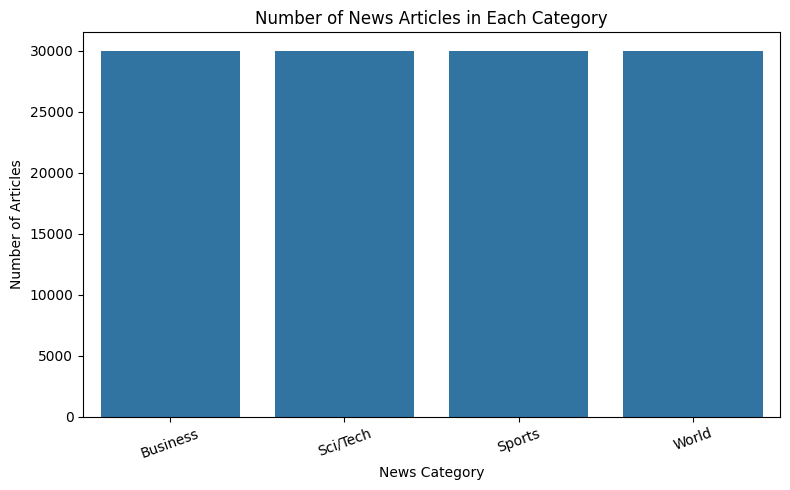

In [26]:
category_counts = train_df["category"].value_counts()

print("Number of articles in each category:")
display(category_counts.to_frame(name="Article Count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=train_df, x="category", order=category_counts.index)
plt.title("Number of News Articles in Each Category")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 4.8 Analyze article length

We calculate the number of words in each article. This helps us understand how short or long the input text is.


count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: word_count, dtype: float64


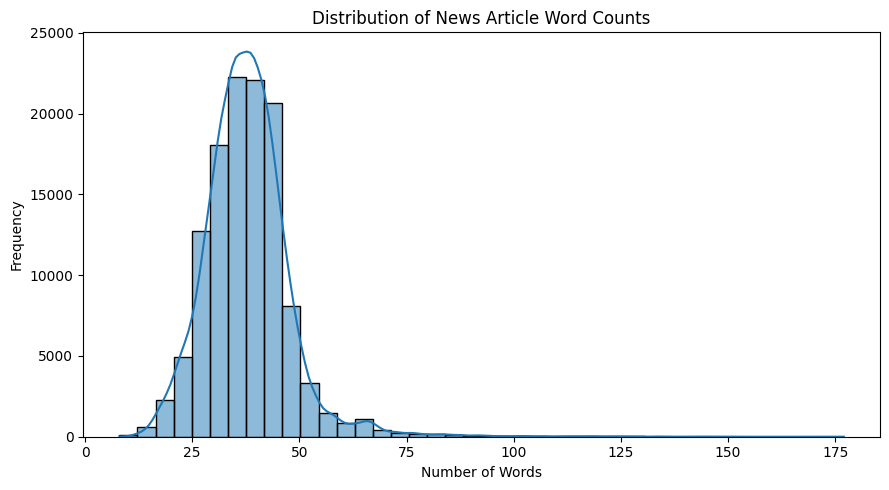

In [27]:
train_df["word_count"] = train_df["text"].astype(str).apply(lambda x: len(x.split()))

print(train_df["word_count"].describe())

plt.figure(figsize=(9, 5))
sns.histplot(data=train_df, x="word_count", bins=40, kde=True)
plt.title("Distribution of News Article Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 4.9 Inspect examples from each category

We display sample articles from each class to understand the type of text and topics present.


In [28]:
for category in sorted(train_df["category"].unique()):
    print("\\nCATEGORY:", category)
    display(train_df.loc[train_df["category"] == category, ["title", "description"]].head(3))

\nCATEGORY: Business


,title,description
0,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again."
1,Carlyle Looks Toward Commercial Aerospace (Reuters),"Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\contr..."
2,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over...


\nCATEGORY: Sci/Tech


,title,description
78,"'Madden,' 'ESPN' Football Score in Different Ways (Reuters)",Reuters - Was absenteeism a little high\on Tuesday among the guys at the office? EA Sports would like\to think it wa...
79,Group to Propose New High-Speed Wireless Format (Reuters),"Reuters - A group of technology companies\including Texas Instruments Inc. (TXN.N), STMicroelectronics\(STM.PA) and ..."
80,AOL to Sell Cheap PCs to Minorities and Seniors (Reuters),Reuters - America Online on Thursday said it\plans to sell a low-priced PC targeting low-income and minority\househo...


\nCATEGORY: Sports


,title,description
448,"Phelps, Thorpe Advance in 200 Freestyle (AP)","AP - Michael Phelps took care of qualifying for the Olympic 200-meter freestyle semifinals Sunday, and then found ou..."
449,Reds Knock Padres Out of Wild-Card Lead (AP),"AP - Wily Mo Pena homered twice and drove in four runs, helping the Cincinnati Reds beat the San Diego Padres 11-5 o..."
450,"Dreaming done, NBA stars awaken to harsh Olympic reality (AFP)",AFP - National Basketball Association players trying to win a fourth consecutive Olympic gold medal for the United S...


\nCATEGORY: World


,title,description
492,Venezuelans Vote Early in Referendum on Chavez Rule (Reuters),Reuters - Venezuelans turned out early\and in large numbers on Sunday to vote in a historic referendum\that will eit...
493,S.Koreans Clash with Police on Iraq Troop Dispatch (Reuters),"Reuters - South Korean police used water cannon in\central Seoul Sunday to disperse at least 7,000 protesters\urging..."
494,Palestinians in Israeli Jails Start Hunger Strike (Reuters),"Reuters - Thousands of Palestinian\prisoners in Israeli jails began a hunger strike for better\conditions Sunday, bu..."


## 4.10 EDA observations

After running the cells, write observations based on your actual output:
- How many rows and columns are present?
- Are there missing values?
- Are duplicate rows present?
- Which categories have the most and fewest articles?
- What does the article word-count distribution look like?

Do not write assumed results. Use the values shown by your notebook.


# STEP 5 – FEATURE ENGINEERING

## 5.1 What is feature engineering?

Feature engineering means creating or transforming input variables so that a machine learning model can learn useful patterns.

Machine learning algorithms cannot directly work with raw sentences as ordinary text. We need to represent text numerically.

## 5.2 Feature used in this project

We combine:
- News title.
- News description.

The combined text is our main feature.

## 5.3 TF-IDF vectorization

TF-IDF stands for **Term Frequency–Inverse Document Frequency**.

It converts words into numerical values based on how important they are in a document compared with the full collection of documents.

- **Term Frequency (TF):** How often a term appears in a document.
- **Inverse Document Frequency (IDF):** Reduces the weight of terms that appear in many documents.

We use:
- Unigrams: single words, such as `market`.
- Bigrams: two adjacent words, such as `stock market`.

The TF-IDF vectorizer will be placed inside a machine learning pipeline. It will learn its vocabulary and IDF values only from training data to prevent data leakage.


# STEP 6 – INPUT AND OUTPUT SEPARATION

## 6.1 Why do we separate input and output?

A supervised machine learning model learns a relationship between input features and known target labels.

For this project:
- `X` contains the news article text.
- `y` contains the category to predict.

We remove rows with missing text or category before separating the variables.


In [29]:
# Keep only rows that have both text and a category
train_df = train_df.dropna(subset=["text", "category"]).copy()
test_df = test_df.dropna(subset=["text", "category"]).copy()

# Input feature
X = train_df["text"].astype(str)

# Target output
y = train_df["category"].astype(str)

# Official test data is kept separately for final evaluation
X_test = test_df["text"].astype(str)
y_test = test_df["category"].astype(str)

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Test input shape:", X_test.shape)
print("Test target shape:", y_test.shape)

print("\\nTarget classes:")
print(sorted(y.unique()))

Input shape: (120000,)
Target shape: (120000,)
Test input shape: (7600,)
Test target shape: (7600,)
\nTarget classes:
['Business', 'Sci/Tech', 'Sports', 'World']


# STEP 7 – TRAIN-TEST SPLIT

## 7.1 Why do we split data?

We need data to train the model and separate data to evaluate it.

For this project, AG News already provides an official test partition. We keep it untouched for the final evaluation.

We split the official training partition into:
- **Training subset (80%):** used to fit candidate models.
- **Validation subset (20%):** used to compare candidate models.

The `stratify=y` argument preserves approximately the same category proportions in both subsets.


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training subset:", X_train.shape)
print("Validation subset:", X_valid.shape)
print("Official test subset:", X_test.shape)

Training subset: (96000,)
Validation subset: (24000,)
Official test subset: (7600,)


# STEP 8 – TEXT PREPROCESSING PIPELINE

## 8.1 What is text preprocessing?

Text preprocessing means cleaning and preparing raw text before converting it into numerical features.

News text may contain uppercase letters, HTML fragments, URLs, punctuation, and inconsistent spacing. We standardize the text to make it easier to process.

## 8.2 Preprocessing steps

1. **Lowercasing:** Convert uppercase letters into lowercase.
2. **HTML handling:** Remove HTML tags and decode HTML entities.
3. **URL removal:** Remove web addresses.
4. **Punctuation handling:** Remove unnecessary punctuation.
5. **Whitespace handling:** Remove extra spaces.
6. **Tokenization:** Split text into word tokens. TF-IDF performs tokenization internally.
7. **Vocabulary creation:** TF-IDF learns a vocabulary from the training text.
8. **Stop-word filtering:** Remove common English words when useful.
9. **Stemming or lemmatization:** Optional word normalization. We do not apply it in this baseline because it can sometimes remove useful distinctions in news text.

## 8.3 Create a text-cleaning function

A function allows us to apply the same cleaning operations to every article. The function is passed to the TF-IDF vectorizer later.


In [31]:
import re
import html

def clean_text(text):
    # Convert the input to a string
    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Convert all characters to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)

    # Keep letters, numbers, and spaces
    text = re.sub(r"[^a-z0-9\\s]", " ", text)

    # Replace repeated whitespace with one space
    text = re.sub(r"\\s+", " ", text).strip()

    return text

sample_text = "BREAKING NEWS! Visit https://example.com for the latest update."
print("Original text:")
print(sample_text)

print("\\nCleaned text:")
print(clean_text(sample_text))

Original text:
BREAKING NEWS! Visit https://example.com for the latest update.
\nCleaned text:
breaking news  visit https   example com for the latest update


## 8.4 Tokenization example

Tokenization means splitting a sentence into smaller units called tokens. In our model, the TF-IDF vectorizer will tokenize the cleaned text internally.


In [32]:
sample_sentence = "Machine learning helps classify news articles."

tokens = clean_text(sample_sentence).split()

print("Tokens:")
print(tokens)

Tokens:
['machine', 'learning', 'helps', 'classify', 'news', 'articles']


## 8.5 Vocabulary creation

A vocabulary is the collection of unique terms learned from the training documents. We will let `TfidfVectorizer` build this vocabulary during pipeline fitting.

**Important:** Do not fit a vectorizer on the complete dataset before splitting. That would allow information from validation or test data to influence feature construction.


# STEP 9 – MODEL BUILDING

## 9.1 What is model building?

Model building means training machine learning algorithms using the training data so that they can learn patterns between article text and category labels.

We compare three algorithms:

### A. Multinomial Naive Bayes
A probabilistic classification algorithm commonly used for text classification. It is a useful baseline for word-frequency-based features such as TF-IDF.

### B. Logistic Regression
A classification algorithm that learns weights for input features and predicts one of multiple classes.

### C. Linear Support Vector Machine (Linear SVM)
A model that learns decision boundaries between classes. Linear SVM often performs well with high-dimensional sparse text features.

## 9.2 Create the TF-IDF and model pipeline

A pipeline ensures that text cleaning, vectorization, and classification are applied consistently. During fitting, the vocabulary is learned only from the training subset.


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

def create_pipeline(classifier):
    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                preprocessor=clean_text,
                stop_words="english",
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True,
                max_features=150000
            )
        ),
        ("classifier", classifier)
    ])
    return pipeline

print("Pipeline function created successfully.")

Pipeline function created successfully.


## 9.3 Define the candidate models

We create one pipeline for each algorithm. All three models use the same text-processing and TF-IDF settings so that their validation performance can be compared.


In [34]:
models = {
    "Multinomial Naive Bayes": create_pipeline(MultinomialNB()),
    "Logistic Regression": create_pipeline(
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Linear SVM": create_pipeline(
        LinearSVC(random_state=42)
    )
}

print("Candidate models:")
for model_name in models:
    print("-", model_name)

Candidate models:
- Multinomial Naive Bayes
- Logistic Regression
- Linear SVM


## 9.4 Train the models

The `fit()` method trains each model using the training subset. We then predict the category for validation articles.


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

validation_results = []
trained_models = {}

for model_name, model in models.items():
    print("Training:", model_name)

    # Learn TF-IDF features and train the classifier
    model.fit(X_train, y_train)

    # Predict categories for validation data
    y_valid_pred = model.predict(X_valid)

    # Calculate validation metrics
    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_valid, y_valid_pred),
        "Precision": precision_score(
            y_valid, y_valid_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_valid_pred, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_valid, y_valid_pred, average="weighted", zero_division=0
        )
    })

    trained_models[model_name] = model

results_df = pd.DataFrame(validation_results)
results_df = results_df.sort_values(by="F1-score", ascending=False)

display(results_df)

Training: Multinomial Naive Bayes
Training: Logistic Regression
Training: Linear SVM


,Model,Accuracy,Precision,Recall,F1-score
2,Linear SVM,0.923792,0.923712,0.923792,0.923688
1,Logistic Regression,0.919500,0.919420,0.919500,0.919389
0,Multinomial Naive Bayes,0.913667,0.913479,0.913667,0.913469


# STEP 10 – MODEL EVALUATION

## 10.1 Why do we evaluate a model?

Evaluation helps us understand how accurately the trained model predicts categories for data it did not use during training.

We use the validation set to compare the candidate models.

## 10.2 Evaluation metrics

- **Accuracy:** Fraction of all predictions that are correct.
- **Precision:** Of the items predicted as a class, how many truly belong to that class.
- **Recall:** Of the actual items in a class, how many the model correctly identifies.
- **F1-score:** Harmonic mean of precision and recall.
- **Confusion matrix:** Shows correct and incorrect predictions for each class.

We use weighted averages for precision, recall, and F1-score. Weighted metrics account for the number of examples in each category.


In [36]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Select the model with the highest validation weighted F1-score
best_baseline_name = results_df.iloc[0]["Model"]
best_baseline_model = trained_models[best_baseline_name]

# Generate validation predictions
best_valid_predictions = best_baseline_model.predict(X_valid)

print("Best baseline model:", best_baseline_name)
print("\\nClassification report:")
print(
    classification_report(
        y_valid,
        best_valid_predictions,
        zero_division=0
    )
)

Best baseline model: Linear SVM
\nClassification report:
              precision    recall  f1-score   support

    Business       0.90      0.90      0.90      6000
    Sci/Tech       0.90      0.90      0.90      6000
      Sports       0.96      0.98      0.97      6000
       World       0.94      0.91      0.92      6000

    accuracy                           0.92     24000
   macro avg       0.92      0.92      0.92     24000
weighted avg       0.92      0.92      0.92     24000



## 10.3 Confusion matrix

The confusion matrix compares actual categories with predicted categories. Correct predictions appear on the diagonal. Off-diagonal values show classification errors.


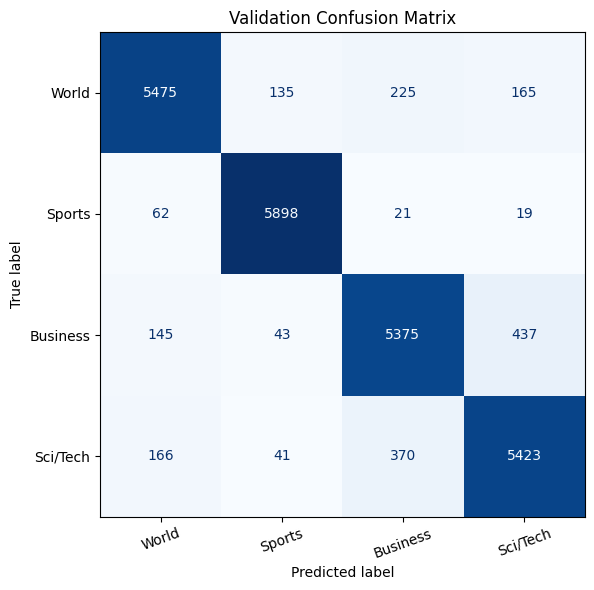

In [37]:
category_order = ["World", "Sports", "Business", "Sci/Tech"]

cm = confusion_matrix(
    y_valid,
    best_valid_predictions,
    labels=category_order
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=category_order
)

fig, ax = plt.subplots(figsize=(8, 6))
display_cm.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Validation Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# STEP 11 – HYPERPARAMETER TUNING

## 11.1 What is hyperparameter tuning?

Hyperparameters are settings chosen before model training. Tuning means testing different settings to find a combination that performs well.

We use `GridSearchCV` to test combinations with cross-validation.

## 11.2 Parameters we tune

Depending on which baseline model ranked first:
- TF-IDF `ngram_range`: unigrams only or unigrams plus bigrams.
- TF-IDF `min_df`: minimum number of documents in which a term must appear.
- Naive Bayes `alpha`: smoothing strength.
- Logistic Regression or Linear SVM `C`: regularization strength.

The tuning uses the training subset only. The validation and official test data are not used to fit the grid search.


In [38]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define a parameter grid for the best baseline algorithm
if best_baseline_name == "Multinomial Naive Bayes":
    parameter_grid = {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [2, 5],
        "classifier__alpha": [0.1, 0.5, 1.0]
    }

elif best_baseline_name == "Logistic Regression":
    parameter_grid = {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [2, 5],
        "classifier__C": [0.5, 1.0, 2.0]
    }

else:
    parameter_grid = {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [2, 5],
        "classifier__C": [0.5, 1.0, 2.0]
    }

# Stratified cross-validation keeps class proportions similar in each fold
cross_validation = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=models[best_baseline_name],
    param_grid=parameter_grid,
    scoring="f1_weighted",
    cv=cross_validation,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\\nBest cross-validation weighted F1-score:")
print(grid_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'classifier__C': 0.5, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
\nBest cross-validation weighted F1-score:
0.9216054309530982


# STEP 12 – BEST MODEL SELECTION AND FINAL EVALUATION

## 12.1 Select the best tuned model

Grid search returns the best estimator based on the selected scoring metric. We select that complete pipeline.

## 12.2 Train using all official training data

After model selection, we fit the selected pipeline on all of the official training partition, including the validation examples. The official test partition remains untouched.

## 12.3 Final evaluation

We evaluate the final model on the official test set. These results provide the final held-out evaluation for this project.


In [39]:
# Select the best pipeline found by GridSearchCV
best_model = grid_search.best_estimator_

# Refit the selected pipeline using all official training examples
best_model.fit(X, y)

# Predict the category of each official test article
y_test_pred = best_model.predict(X_test)

# Calculate final evaluation metrics
final_accuracy = accuracy_score(y_test, y_test_pred)
final_precision = precision_score(
    y_test, y_test_pred, average="weighted", zero_division=0
)
final_recall = recall_score(
    y_test, y_test_pred, average="weighted", zero_division=0
)
final_f1 = f1_score(
    y_test, y_test_pred, average="weighted", zero_division=0
)

print("FINAL TEST RESULTS")
print("------------------")
print("Accuracy:", round(final_accuracy, 4))
print("Weighted Precision:", round(final_precision, 4))
print("Weighted Recall:", round(final_recall, 4))
print("Weighted F1-score:", round(final_f1, 4))

FINAL TEST RESULTS
------------------
Accuracy: 0.9262
Weighted Precision: 0.9261
Weighted Recall: 0.9262
Weighted F1-score: 0.926


## 12.4 Final classification report

The classification report provides precision, recall, F1-score, and support for each category. Support is the number of actual test examples in that category.


In [40]:
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=category_order,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       World       0.94      0.91      0.93      1900
      Sports       0.96      0.99      0.97      1900
    Business       0.90      0.89      0.90      1900
    Sci/Tech       0.90      0.91      0.90      1900

    accuracy                           0.93      7600
   macro avg       0.93      0.93      0.93      7600
weighted avg       0.93      0.93      0.93      7600



## 12.5 Final confusion matrix

This matrix helps us identify which news categories the model confuses with one another.


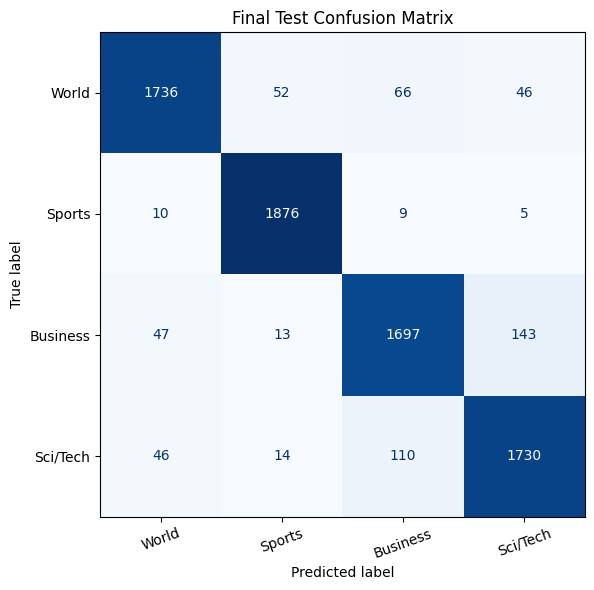

In [41]:
final_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=category_order
)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=category_order
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

plt.title("Final Test Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# STEP 13 – SAVE AND LOAD THE MODEL

## 13.1 Why save the model?

Training can take time. Saving the trained pipeline allows us to use it later without training it again.

We save the **complete pipeline**, not just the classifier. It includes:
- Text cleaning function.
- TF-IDF vectorizer and learned vocabulary.
- Trained classification algorithm.

## 13.2 Save the model using Joblib

The file will be stored in an `artifacts` folder inside the current notebook directory.


In [42]:
import joblib
from pathlib import Path

# Create a folder for saved project files
artifact_folder = Path("artifacts")
artifact_folder.mkdir(exist_ok=True)

# Define the model file path
model_file = artifact_folder / "news_article_classifier.joblib"

# Save the complete trained pipeline
joblib.dump(best_model, model_file)

print("Model saved successfully.")
print("Saved location:", model_file.resolve())

Model saved successfully.
Saved location: C:\Users\bhuva\ML\NLP\Practice\Sony\artifacts\news_article_classifier.joblib


## 13.3 Load the saved model

We load the pipeline from the saved file. The loaded pipeline can process raw article text and predict a category.


In [43]:
loaded_model = joblib.load(model_file)

print("Saved model loaded successfully.")

Saved model loaded successfully.


## 13.4 Test the loaded model

We give one new article to the loaded model and check its predicted category.


In [44]:
sample_article = (
    "The company reported higher profits after strong sales in the global market."
)

loaded_prediction = loaded_model.predict([sample_article])

print("News article:")
print(sample_article)
print("\\nPredicted category:")
print(loaded_prediction[0])

News article:
The company reported higher profits after strong sales in the global market.
\nPredicted category:
Business


# STEP 14 – MODEL DEPLOYMENT USING GRADIO

## 14.1 What is deployment?

Deployment means making a trained model available through an interface so that another person can use it.

For this project, we create a simple Gradio application. A user enters a news article, clicks Submit, and sees the predicted category.

## 14.2 Install and import Gradio

If Gradio was installed in Step 3, this import should work.


In [45]:
import gradio as gr

print("Gradio imported successfully.")

Gradio imported successfully.


## 14.3 Create the prediction function

The function accepts raw text, checks whether the input is empty, and passes the article to the saved pipeline. The pipeline performs cleaning and TF-IDF transformation before classification.


In [46]:
def predict_news_category(article):
    # Check for empty input
    if article is None or str(article).strip() == "":
        return "Please enter a news article."

    # Predict using the complete saved pipeline
    prediction = loaded_model.predict([str(article)])[0]

    return "Predicted News Category: " + prediction

## 14.4 Build the Gradio interface

We define a text box for the article and a text output for the prediction. `demo.launch()` starts the application from the notebook.


In [47]:
demo = gr.Interface(
    fn=predict_news_category,
    inputs=gr.Textbox(
        lines=8,
        label="Enter News Article",
        placeholder="Paste a news headline or article here..."
    ),
    outputs=gr.Textbox(label="Predicted Category"),
    title="News Article Classification System",
    description=(
        "This NLP application classifies news articles into "
        "World, Sports, Business, or Sci/Tech."
    )
)

# Launch the application locally
demo.launch(share=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


### How to use the application

1. Run the Gradio launch cell.
2. Open the local link displayed by Gradio.
3. Enter or paste a news headline or article.
4. Submit the text.
5. Read the predicted category.

For a temporary public demo link, you can change `share=False` to `share=True`. Do not enter confidential or private text into a public demo.


# STEP 15 – MODEL MONITORING

## 15.1 What is model monitoring?

Model monitoring means checking the deployed model over time to make sure it continues to work properly.

News topics and writing styles change. A model that worked well earlier may become less accurate when new topics or language patterns appear.

## 15.2 What should we monitor?

- Number of predictions in each category.
- Empty or unusually short inputs.
- Prediction errors reported by users.
- Changes in words and topics over time (data drift).
- Accuracy, precision, recall, and F1-score when verified labels become available.

## 15.3 Create a simple prediction log

This example records the time, predicted category, and input word count. It deliberately does not store the full article text.


In [48]:
import csv
from datetime import datetime, timezone
from pathlib import Path

log_file = Path("prediction_log.csv")

def predict_and_log(article):
    article = str(article).strip()

    if not article:
        raise ValueError("Please provide a non-empty news article.")

    # Predict category
    predicted_category = loaded_model.predict([article])[0]

    # Prepare a simple monitoring record
    record = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "predicted_category": predicted_category,
        "word_count": len(article.split())
    }

    # Append the record to a CSV file
    file_exists = log_file.exists()

    with open(log_file, "a", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=record.keys())

        if not file_exists:
            writer.writeheader()

        writer.writerow(record)

    return predicted_category

monitoring_example = (
    "The national team won the championship after a close final match."
)

print("Prediction:", predict_and_log(monitoring_example))
print("Monitoring record saved to:", log_file.resolve())

Prediction: Sports
Monitoring record saved to: C:\Users\bhuva\ML\NLP\Practice\Sony\prediction_log.csv


## 15.4 View the prediction log

We can inspect the log to understand the number and type of predictions made by the application.


In [49]:
if log_file.exists():
    monitoring_df = pd.read_csv(log_file)
    display(monitoring_df.tail(10))

    if not monitoring_df.empty:
        print("Prediction counts:")
        display(
            monitoring_df["predicted_category"]
            .value_counts()
            .to_frame("Prediction Count")
        )
else:
    print("No prediction records are available yet.")

,timestamp_utc,predicted_category,word_count
0,2026-11-12T09:40:25.902947+00:00,Sports,11


Prediction counts:


,Prediction Count
predicted_category,
Sports,1


# ADDITIONAL SECTION – SAMPLE PREDICTIONS

## Test the model with sample news articles

We test the trained model with different example topics. The model will generate the predictions when you execute the cell. The examples are not guaranteed labels; inspect the actual predictions.


In [50]:
sample_articles = [
    "The national team won the final match after scoring two goals.",
    "A technology company introduced a new artificial intelligence processor.",
    "Global leaders met to discuss international trade and security.",
    "The stock market increased after several companies reported higher profits."
]

sample_predictions = loaded_model.predict(sample_articles)

sample_results = pd.DataFrame({
    "News Article": sample_articles,
    "Predicted Category": sample_predictions
})

display(sample_results)

,News Article,Predicted Category
0,The national team won the final match after scoring two goals.,Sports
1,A technology company introduced a new artificial intelligence processor.,Sci/Tech
2,Global leaders met to discuss international trade and security.,World
3,The stock market increased after several companies reported higher profits.,Business


# PROJECT CONCLUSION AND RESULTS

## Project summary

In this project, we developed a news article classification system using Natural Language Processing and Machine Learning. We used the AG News dataset, explored the data, prepared article text, converted text into numerical TF-IDF features, and compared multiple classification algorithms.

We tuned the strongest baseline model using cross-validation, evaluated the selected model on the official test partition, saved and loaded the complete pipeline, and created a Gradio interface for predictions.

## Enter your actual results

Fill in these values after running the final evaluation cells:

| Evaluation metric | Your result |
|---|---|
| Best algorithm | Write the selected algorithm |
| Test accuracy | Copy the printed value |
| Weighted precision | Copy the printed value |
| Weighted recall | Copy the printed value |
| Weighted F1-score | Copy the printed value |

## Limitations

1. The model predicts only four categories.
2. An article outside these categories may still be forced into one of them.
3. Very short or ambiguous text may be difficult to classify.
4. The model may perform differently on news sources or writing styles not represented in its training data.
5. Monitoring requires verified labels to measure real-world accuracy.

## Future improvements

- Add more news categories.
- Train with newer and more diverse news articles.
- Compare with transformer models such as DistilBERT or BERT.
- Collect verified feedback and retrain when necessary.
- Add calibrated confidence scores if the application needs them.

## Final conclusion

This project demonstrates an end-to-end NLP workflow for multi-class text classification. It shows how raw news text can be transformed into numerical features, used to train machine learning models, evaluated, saved, and deployed as a practical application.

